# Classificação de Espécies de Corujas com CNN Própria — v2

Esta versão mantém uma **arquitetura convolucional implementada pelo projeto**, sem transfer learning. Em relação à versão anterior, corrige:

- ausência de `y_previstos` na avaliação;
- ausência de conjunto de teste independente;
- ausência de métricas por classe e de matriz de confusão normalizada;
- ausência de pesos para compensar o desbalanceamento;
- uso de `Flatten` + `Dense`, que concentrava cerca de 11 milhões de parâmetros;
- validação embaralhada e contagem de arquivos que não eram necessariamente imagens;
- download/descompactação sem verificação de erro;
- ausência de salvamento do modelo e da ordem das classes.

A arquitetura agora usa blocos convolucionais com `BatchNorm`, `GlobalAveragePooling2D`, `Dropout`, pesos de classe suavizados, `ReduceLROnPlateau` e `EarlyStopping`. O treino e o teste usam divisões estratificadas 70/15/15.

**Importante:** as saídas desta versão ainda não foram executadas. Os números de acurácia e F1 devem ser preenchidos após rodar o notebook no Colab. Não é possível garantir um valor sem executar o experimento.


## 1. Bibliotecas e reprodutibilidade

No Colab, o TensorFlow já vem instalado. Não é necessário reinstalá-lo. Para execução local, crie um ambiente com TensorFlow compatível antes de rodar.


In [1]:
%pip install -q numpy pandas matplotlib scikit-learn gdown

import json
import shutil
import sys
import time
from pathlib import Path

import gdown
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras import callbacks, layers, models

SEMENTE = 42
tf.keras.utils.set_random_seed(SEMENTE)

print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__, '| Pandas:', pd.__version__)
print('Scikit-learn:', sklearn.__version__)
print('TensorFlow:', tf.__version__)
print('GPUs:', tf.config.list_physical_devices('GPU'))


Python: 3.13.16
NumPy: 2.4.6 | Pandas: 2.2.3
Scikit-learn: 1.6.1
TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Download e organização da base

O ZIP deve conter a pasta `imgs/` ou as pastas das espécies diretamente. O destino final deve ser `/content/imgs/<espécie>/arquivo`.


In [2]:
FILE_ID = '1fq87mnV4pG1PSV_qwWM3-IXlkWL4O6is'
DATA_DIR = Path('/content/imgs')
ZIP_PATH = Path('/content/imgs.zip')

if not DATA_DIR.is_dir():
    url = f'https://drive.google.com/uc?id={FILE_ID}'
    gdown.download(url, output=str(ZIP_PATH), quiet=False)

    import zipfile
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall('/content')
    ZIP_PATH.unlink(missing_ok=True)

# Se o ZIP contiver images/ em vez de imgs/, corrige o nome da raiz.
if not DATA_DIR.is_dir() and Path('/content/images').is_dir():
    Path('/content/images').rename(DATA_DIR)

if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f'Diretório não encontrado: {DATA_DIR}. '
        'Verifique a estrutura do ZIP e ajuste DATA_DIR.'
    )

print('Base pronta em:', DATA_DIR)


Downloading...
From (original): https://drive.google.com/uc?id=1fq87mnV4pG1PSV_qwWM3-IXlkWL4O6is
From (redirected): https://drive.google.com/uc?id=1fq87mnV4pG1PSV_qwWM3-IXlkWL4O6is&confirm=t&uuid=48aa5726-b34a-4327-bfa2-78c4764bacdf
To: /content/imgs.zip
100%|██████████| 985M/985M [00:11<00:00, 85.9MB/s]


Base pronta em: /content/imgs


## 3. Contagem e validação das classes

Somente arquivos com extensão de imagem são contados. Pastas ocultas, `__MACOSX` e classes vazias são tratadas explicitamente para evitar classes fantasmas.


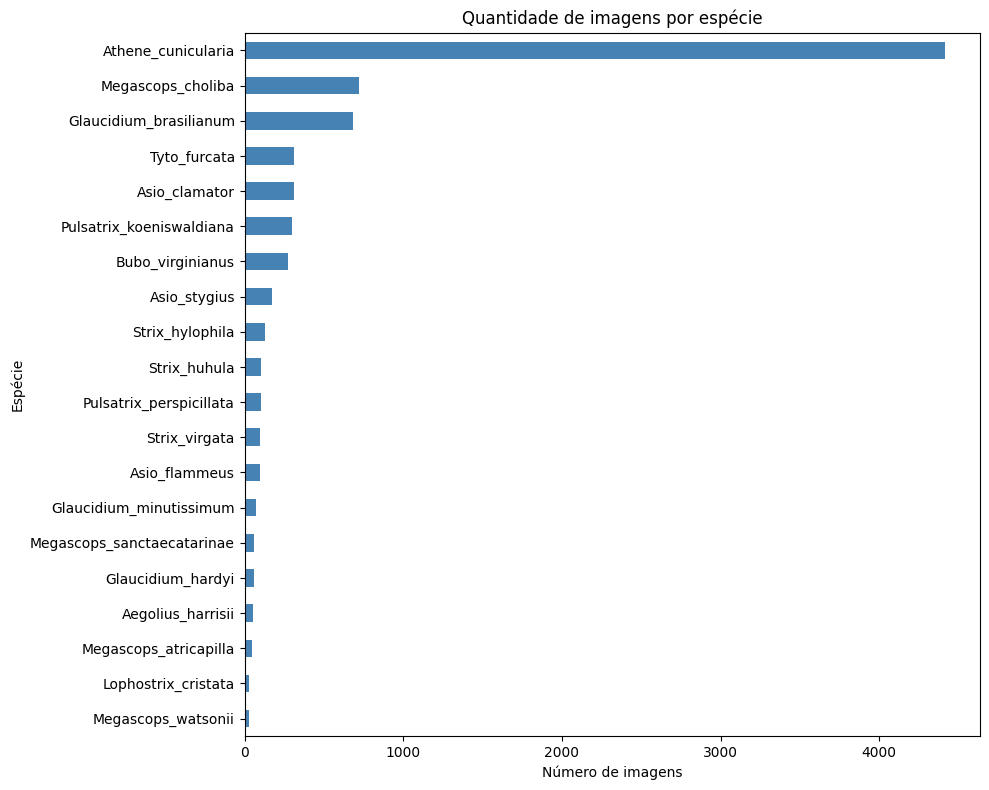

Total de classes: 20
Total de imagens: 8067
Megascops_watsonii              26
Lophostrix_cristata             27
Megascops_atricapilla           44
Aegolius_harrisii               55
Glaucidium_hardyi               57
Megascops_sanctaecatarinae      58
Glaucidium_minutissimum         74
Asio_flammeus                   96
Strix_virgata                   96
Pulsatrix_perspicillata        105
Strix_huhula                   106
Strix_hylophila                131
Asio_stygius                   175
Bubo_virginianus               271
Pulsatrix_koeniswaldiana       300
Asio_clamator                  310
Tyto_furcata                   312
Glaucidium_brasilianum         686
Megascops_choliba              723
Athene_cunicularia            4415


In [3]:
EXTENSOES_IMAGEM = {'.jpg', '.jpeg', '.png', '.bmp', '.gif'}

nomes_das_classes = sorted(
    p.name for p in DATA_DIR.iterdir()
    if p.is_dir() and not p.name.startswith(('.', '__'))
)

contagem = {}
for classe in nomes_das_classes:
    arquivos = [
        p for p in (DATA_DIR / classe).iterdir()
        if p.is_file() and p.suffix.lower() in EXTENSOES_IMAGEM
    ]
    contagem[classe] = len(arquivos)

if len(nomes_das_classes) != 20:
    raise ValueError(
        f'Esperava 20 classes, encontrei {len(nomes_das_classes)}: '
        f'{nomes_das_classes}'
    )
classes_invalidas = [c for c, n in contagem.items() if n < 2]
if classes_invalidas:
    raise ValueError(f'Classes com menos de 2 imagens: {classes_invalidas}')

contagem_serie = pd.Series(contagem, dtype='int64').sort_values()
contagem_serie.plot.barh(figsize=(10, 8), color='steelblue')
plt.title('Quantidade de imagens por espécie')
plt.xlabel('Número de imagens')
plt.ylabel('Espécie')
plt.tight_layout()
plt.show()

print('Total de classes:', len(nomes_das_classes))
print('Total de imagens:', int(contagem_serie.sum()))
print(contagem_serie.to_string())


## 4. Divisão estratificada e pipeline

A divisão é **70% treino, 15% validação e 15% teste**. O teste não participa do treinamento nem da seleção de épocas. A validação e o teste não são embaralhados, para manter a correspondência entre rótulos e previsões.

Não usamos `cache()` para evitar carregar toda a base decodificada na RAM. As imagens são redimensionadas com `antialias=True`.


In [4]:
tamanho_imagem = (224, 224)
tamanho_lote = 32
num_classes = len(nomes_das_classes)

caminhos = []
rotulos = []
for indice, classe in enumerate(nomes_das_classes):
    arquivos = sorted(
        p for p in (DATA_DIR / classe).iterdir()
        if p.is_file() and p.suffix.lower() in EXTENSOES_IMAGEM
    )
    caminhos.extend(str(p) for p in arquivos)
    rotulos.extend([indice] * len(arquivos))

caminhos = np.asarray(caminhos)
rotulos = np.asarray(rotulos, dtype=np.int32)

caminhos_treino, caminhos_temp, rotulos_treino, rotulos_temp = train_test_split(
    caminhos,
    rotulos,
    test_size=0.30,
    random_state=SEMENTE,
    stratify=rotulos,
)
caminhos_validacao, caminhos_teste, rotulos_validacao, rotulos_teste = train_test_split(
    caminhos_temp,
    rotulos_temp,
    test_size=0.50,
    random_state=SEMENTE,
    stratify=rotulos_temp,
)

AUTOTUNE = tf.data.AUTOTUNE


def carregar_imagem(caminho, rotulo):
    bytes_imagem = tf.io.read_file(caminho)
    imagem = tf.io.decode_image(
        bytes_imagem, channels=3, expand_animations=False
    )
    imagem = tf.image.resize(imagem, tamanho_imagem, antialias=True)
    imagem.set_shape((*tamanho_imagem, 3))
    return imagem, rotulo


def criar_dataset(caminhos_conjunto, rotulos_conjunto, treinamento=False):
    ds = tf.data.Dataset.from_tensor_slices((caminhos_conjunto, rotulos_conjunto))
    ds = ds.map(carregar_imagem, num_parallel_calls=AUTOTUNE)
    if treinamento:
        ds = ds.shuffle(
            buffer_size=min(len(caminhos_conjunto), 4096),
            seed=SEMENTE,
            reshuffle_each_iteration=True,
        )
    return ds.batch(tamanho_lote).prefetch(AUTOTUNE)


dataset_treino = criar_dataset(caminhos_treino, rotulos_treino, treinamento=True)
dataset_validacao = criar_dataset(caminhos_validacao, rotulos_validacao)
dataset_teste = criar_dataset(caminhos_teste, rotulos_teste)

print('Treino:', len(caminhos_treino))
print('Validação:', len(caminhos_validacao))
print('Teste:', len(caminhos_teste))

# Pesos balanceados, suavizados pela raiz quadrada para evitar pesos extremos.
pesos = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(num_classes),
    y=rotulos_treino,
)
pesos = np.sqrt(pesos)
pesos_das_classes = {int(i): float(w) for i, w in enumerate(pesos)}

print('Peso da classe majoritária:', pesos_das_classes[int(np.bincount(rotulos_treino).argmax())])
print('Maior peso:', max(pesos_das_classes.values()))


Treino: 5646
Validação: 1210
Teste: 1211
Peso da classe majoritária: 0.30225688296707304
Maior peso: 3.960218849171512


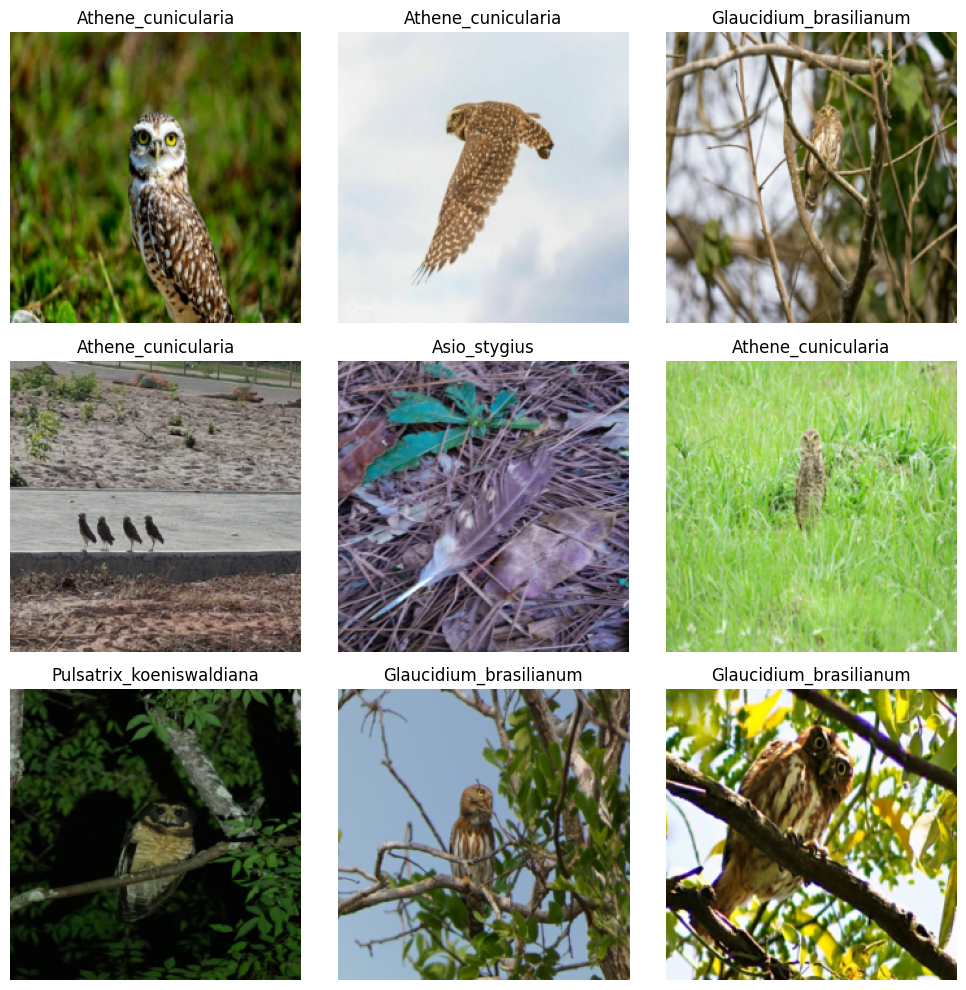

In [5]:
plt.figure(figsize=(10, 10))
for imagens, rotulos_lote in dataset_treino.take(1):
    for i in range(min(9, len(imagens))):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(imagens[i].numpy().astype('uint8'))
        plt.title(nomes_das_classes[int(rotulos_lote[i])])
        plt.axis('off')
plt.tight_layout()
plt.show()


## 5. Arquitetura própria

A rede usa quatro blocos convolucionais. Cada bloco tem duas convoluções 3×3, `BatchNorm`, `ReLU`, `MaxPooling` e `Dropout`.

A principal mudança em relação à versão anterior é a substituição de `Flatten` + `Dense(128)` por `GlobalAveragePooling2D`. Isso elimina a camada de cerca de 11 milhões de parâmetros e reduz o risco de overfitting.


In [6]:
def criar_cnn(num_classes):
    entradas = layers.Input(shape=(*tamanho_imagem, 3), name='imagem')

    x = layers.RandomFlip('horizontal')(entradas)
    x = layers.RandomRotation(0.08, fill_mode='reflect')(x)
    x = layers.RandomZoom(0.10, fill_mode='reflect')(x)
    x = layers.RandomContrast(0.10)(x)
    x = layers.Rescaling(1.0 / 255.0, name='normalizacao')(x)

    for filtros, dropout in [
        (32, 0.15),
        (64, 0.20),
        (128, 0.25),
        (256, 0.30),
    ]:
        for _ in range(2):
            x = layers.Conv2D(
                filtros,
                3,
                padding='same',
                use_bias=False,
                kernel_initializer='he_normal',
            )(x)
            x = layers.BatchNormalization()(x)
            x = layers.Activation('relu')(x)
        x = layers.MaxPooling2D(pool_size=2)(x)
        x = layers.Dropout(dropout)(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.4)(x)
    saidas = layers.Dense(num_classes, activation='softmax', name='especie')(x)

    return models.Model(entradas, saidas, name='cnn_corujas_v2')


modelo = criar_cnn(num_classes)
modelo.summary()


Model: "cnn_corujas_v2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagem (InputLayer)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast                 │ (None, 224, 224, 3)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalizacao (Rescaling)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 56, 56, 64)     │             

 Total params: 1,210,612 (4.62 MB)

 Trainable params: 1,208,692 (4.61 MB)

 Non-trainable params: 1,920 (7.50 KB)

## 6. Treinamento e seleção do melhor modelo

Usamos `Adam`, pesos de classe, `ModelCheckpoint`, `EarlyStopping` e `ReduceLROnPlateau`.

A seleção do melhor modelo é feita por **F1 macro na validação**, e não apenas por `val_loss`. Isso evita que a classe majoritária domine a escolha dos pesos. O callback personalizado calcula o F1 macro ao final de cada época e disponibiliza a métrica para os demais callbacks.


In [8]:
class MetricasValidacao(callbacks.Callback):
    def __init__(self, dataset, rotulos):
        super().__init__()
        self.dataset = dataset
        self.rotulos = np.asarray(rotulos)

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        probabilidades = self.model.predict(self.dataset, verbose=0)
        previstos = np.argmax(probabilidades, axis=1)
        logs['val_f1_macro'] = float(
            f1_score(self.rotulos, previstos, average='macro', zero_division=0)
        )
        logs['val_balanced_accuracy'] = float(
            balanced_accuracy_score(self.rotulos, previstos)
        )


EPOCAS = 35
RUN_DIR = Path('/content/runs') / time.strftime('%Y%m%d-%H%M%S')
RUN_DIR.mkdir(parents=True, exist_ok=True)
CAMINHO_MELHORES = RUN_DIR / 'melhores_pesos_corujas.weights.h5'

modelo.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

history = modelo.fit(
    dataset_treino,
    validation_data=dataset_validacao,
    epochs=EPOCAS,
    class_weight=pesos_das_classes,
    callbacks=[
        # Deve vir antes do ModelCheckpoint e do EarlyStopping.
        MetricasValidacao(dataset_validacao, rotulos_validacao),
        callbacks.ModelCheckpoint(
            str(CAMINHO_MELHORES),
            monitor='val_f1_macro',
            save_best_only=True,
            save_weights_only=True,
            mode='max',
            verbose=1,
        ),
        callbacks.EarlyStopping(
            monitor='val_f1_macro',
            mode='max',
            patience=6,
            restore_best_weights=True,
        ),
        callbacks.ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,
            patience=2,
            min_lr=1e-6,
            verbose=1,
        ),
    ],
    verbose=2,
)

if not CAMINHO_MELHORES.exists():
    raise FileNotFoundError('O treinamento não gerou checkpoint.')
modelo.load_weights(str(CAMINHO_MELHORES))
print('Melhores pesos restaurados:', CAMINHO_MELHORES)


Epoch 1/35

Epoch 1: val_f1_macro improved from None to 0.08521, saving model to /content/runs/20261110-193316/melhores_pesos_corujas.weights.h5

Epoch 1: finished saving model to /content/runs/20261110-193316/melhores_pesos_corujas.weights.h5
177/177 - 108s - 607ms/step - accuracy: 0.5586 - loss: 1.7569 - val_accuracy: 0.5818 - val_loss: 1.4638 - val_f1_macro: 0.0852 - val_balanced_accuracy: 0.1022 - learning_rate: 0.0010
Epoch 2/35

Epoch 2: val_f1_macro improved from 0.08521 to 0.09341, saving model to /content/runs/20261110-193316/melhores_pesos_corujas.weights.h5

Epoch 2: finished saving model to /content/runs/20261110-193316/melhores_pesos_corujas.weights.h5
177/177 - 92s - 519ms/step - accuracy: 0.5491 - loss: 1.7573 - val_accuracy: 0.5736 - val_loss: 1.5176 - val_f1_macro: 0.0934 - val_balanced_accuracy: 0.1161 - learning_rate: 0.0010
Epoch 3/35

Epoch 3: val_f1_macro did not improve from 0.09341

Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
177/

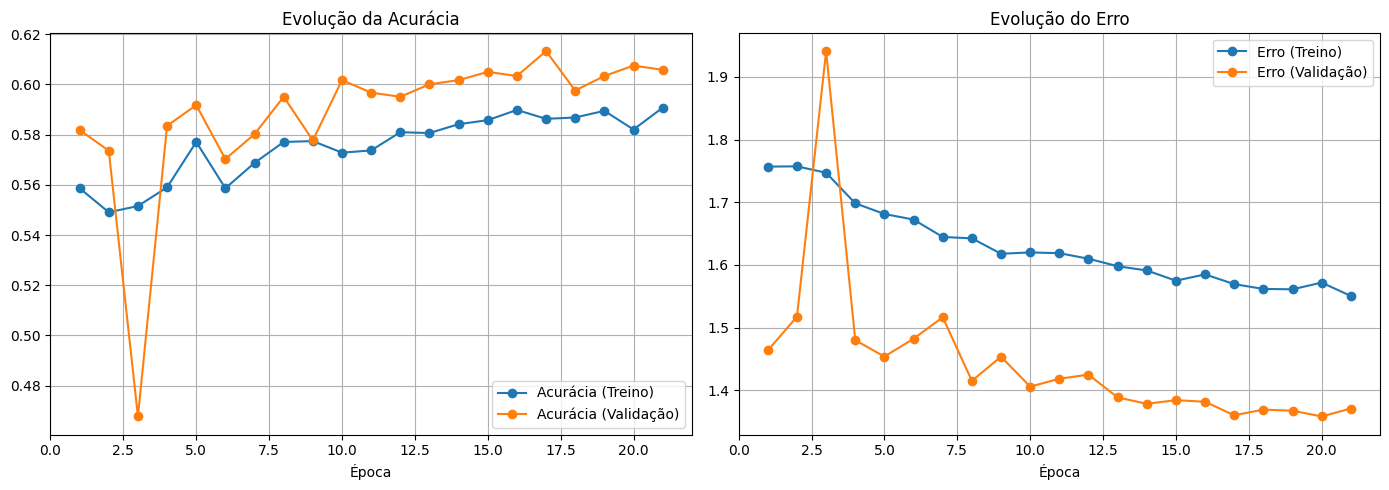

In [9]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epocas = range(1, len(acc) + 1)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epocas, acc, label='Acurácia (Treino)', marker='o')
plt.plot(epocas, val_acc, label='Acurácia (Validação)', marker='o')
plt.xlabel('Época')
plt.title('Evolução da Acurácia')
plt.legend(loc='lower right')
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epocas, loss, label='Erro (Treino)', marker='o')
plt.plot(epocas, val_loss, label='Erro (Validação)', marker='o')
plt.xlabel('Época')
plt.title('Evolução do Erro')
plt.legend(loc='upper right')
plt.grid(True)

plt.tight_layout()
plt.show()


## 7. Avaliação final no teste

Esta avaliação usa apenas o conjunto de teste, que não participou do treinamento nem da seleção de épocas. Além da acurácia global, calculamos acurácia balanceada, precisão, recall e F1 macro. A matriz é normalizada por classe real para facilitar a comparação entre espécies com quantidades diferentes de imagens.


loss_teste: 1.3989
acuracia_teste: 0.6003
acuracia_balanceada: 0.1338
precisao_macro: 0.1413
recall_macro: 0.1338
f1_macro: 0.1266

Relatório por espécie:
                            precision    recall  f1-score   support

         Aegolius_harrisii      0.000     0.000     0.000         8
             Asio_clamator      0.163     0.362     0.225        47
             Asio_flammeus      0.000     0.000     0.000        14
              Asio_stygius      0.000     0.000     0.000        27
        Athene_cunicularia      0.802     0.929     0.861       663
          Bubo_virginianus      0.198     0.390     0.262        41
    Glaucidium_brasilianum      0.488     0.408     0.444       103
         Glaucidium_hardyi      0.000     0.000     0.000         8
   Glaucidium_minutissimum      0.000     0.000     0.000        11
       Lophostrix_cristata      0.000     0.000     0.000         4
     Megascops_atricapilla      0.000     0.000     0.000         6
         Megascops_choliba  

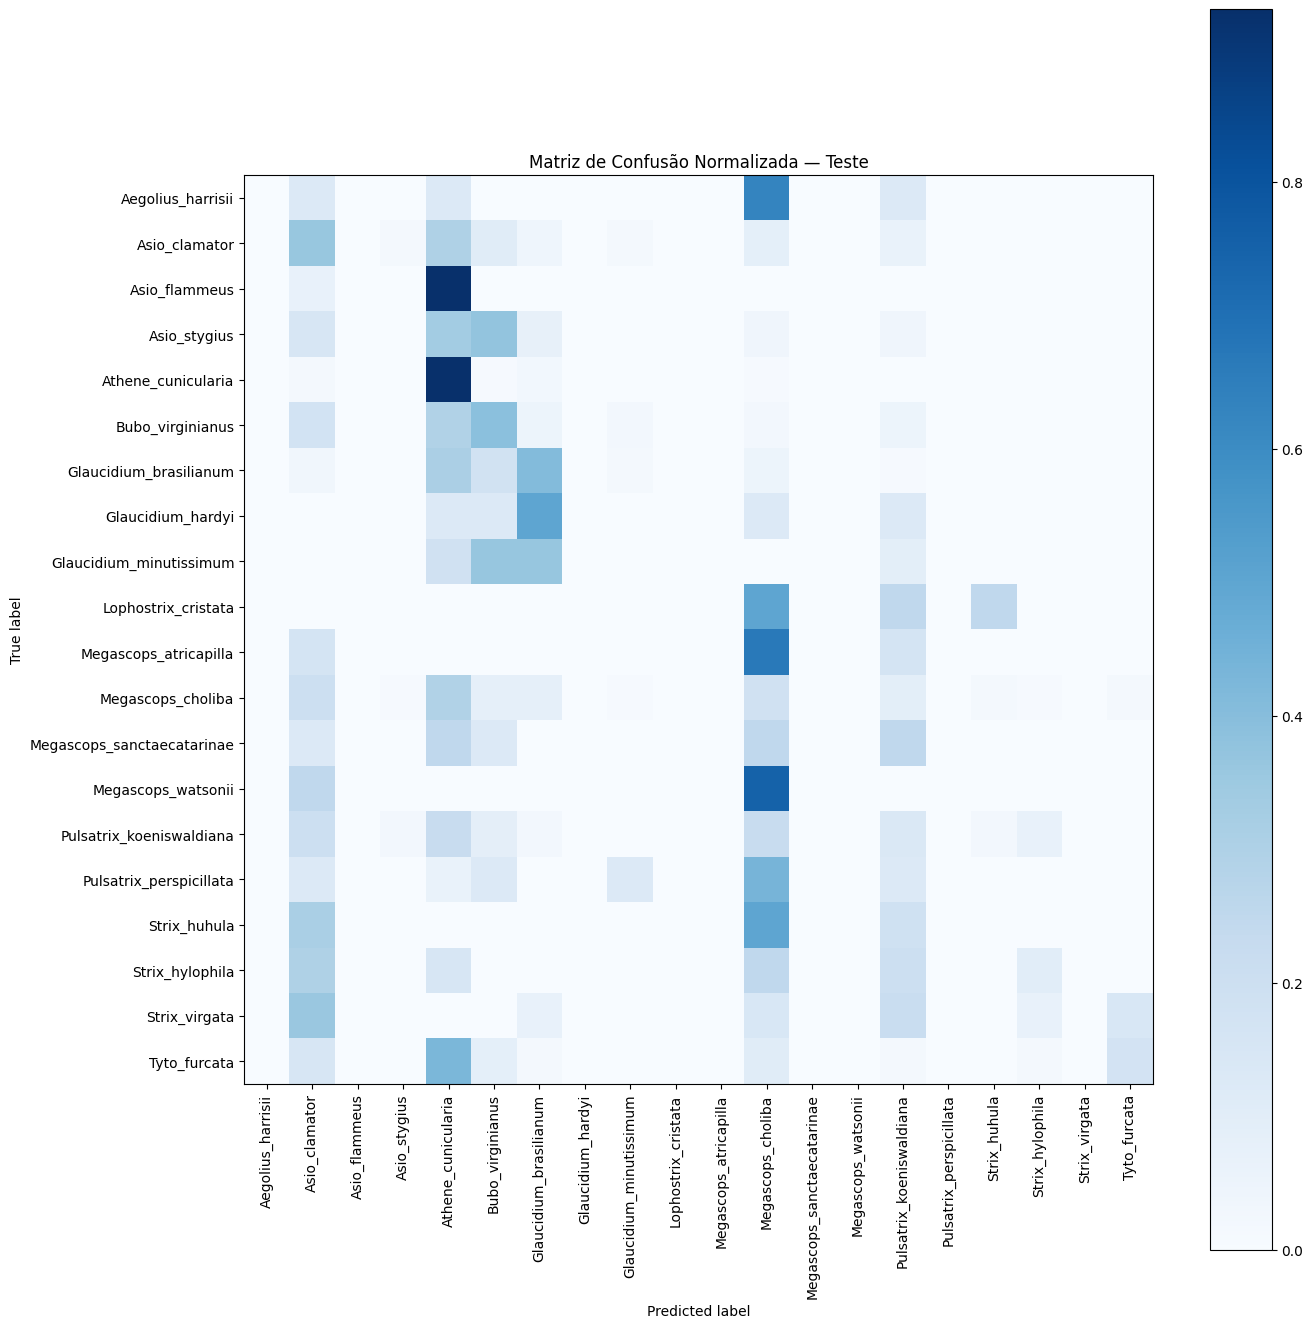

In [10]:
perda_teste, acuracia_keras = modelo.evaluate(dataset_teste, verbose=0)
probabilidades = modelo.predict(dataset_teste, verbose=0)
y_reais = np.asarray(rotulos_teste)
y_previstos = np.argmax(probabilidades, axis=1)

metricas = {
    'loss_teste': float(perda_teste),
    'acuracia_teste': float(accuracy_score(y_reais, y_previstos)),
    'acuracia_balanceada': float(balanced_accuracy_score(y_reais, y_previstos)),
    'precisao_macro': float(precision_score(y_reais, y_previstos, average='macro', zero_division=0)),
    'recall_macro': float(recall_score(y_reais, y_previstos, average='macro', zero_division=0)),
    'f1_macro': float(f1_score(y_reais, y_previstos, average='macro', zero_division=0)),
}

for nome, valor in metricas.items():
    print(f'{nome}: {valor:.4f}')

print('\nRelatório por espécie:')
print(classification_report(
    y_reais,
    y_previstos,
    labels=np.arange(num_classes),
    target_names=nomes_das_classes,
    digits=3,
    zero_division=0,
))

cm = confusion_matrix(
    y_reais,
    y_previstos,
    labels=np.arange(num_classes),
    normalize='true',
)

fig, ax = plt.subplots(figsize=(14, 14))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=nomes_das_classes,
).plot(
    ax=ax,
    xticks_rotation='vertical',
    cmap='Blues',
    colorbar=True,
    include_values=False,
)
plt.title('Matriz de Confusão Normalizada — Teste')
plt.tight_layout()
plt.show()


## 8. Salvamento para demonstração

Salvamos o modelo completo, a ordem das classes, as métricas e algumas imagens de exemplo no Google Drive. O notebook `demo_corujas.ipynb` pode carregar estes artefatos depois.


In [11]:
from google.colab import drive
drive.mount('/content/drive')

SAVE_DIR = Path('/content/drive/MyDrive/ia_corujas_v2')
SAVE_DIR.mkdir(parents=True, exist_ok=True)

modelo.save(str(SAVE_DIR / 'classificador_corujas_v2.keras'))
(SAVE_DIR / 'class_names.json').write_text(
    json.dumps(nomes_das_classes, ensure_ascii=False, indent=2),
    encoding='utf-8',
)
(SAVE_DIR / 'metricas.json').write_text(
    json.dumps(metricas, ensure_ascii=False, indent=2),
    encoding='utf-8',
)
shutil.copy2(CAMINHO_MELHORES, SAVE_DIR / 'melhores_pesos_corujas.weights.h5')

EXEMPLOS = SAVE_DIR / 'exemplos'
EXEMPLOS.mkdir(exist_ok=True)
for caminho in list(map(str, caminhos_teste))[:10]:
    shutil.copy2(caminho, EXEMPLOS / Path(caminho).name)

print('Artefatos salvos em:', SAVE_DIR)


Mounted at /content/drive
Artefatos salvos em: /content/drive/MyDrive/ia_corujas_v2


## 9. Conclusão

Esta versão corrige os bugs de avaliação e torna a arquitetura própria mais eficiente. Os pontos que devem ser analisados após a execução são:

1. **Acurácia de teste** versus a acurácia de validação.
2. **F1 macro e acurácia balanceada**, para verificar se o modelo depende da classe majoritária.
3. **Recall por espécie**, especialmente nas classes com poucas imagens.
4. **Principais confusões** na matriz normalizada.
5. Comparação com a versão anterior usando o mesmo conjunto de teste, se houver interesse em medir o ganho de forma rigorosa.

O modelo continua fechado em 20 espécies. Para uso real, seria necessário validar com imagens de campo, calibrar a confiança e tratar imagens desconhecidas ou sem coruja.
